# TON-IoT Ablation 1: CNN + Transformer Only (No BiLSTM)

Removes the **BiLSTM** component. CNN → Positional Encoding → Transformer → GlobalAvgPool → Classifier.

- Dataset: TON-IoT (`train_test_network.csv`)
- 44 features | Unseen class: `Scanning`
- CNN channels: 64 → 128 | Transformer d_model=128, nhead=4
- Emerging **excluded** from confusion matrix & all metrics

In [1]:
!pip install torch pandas numpy scikit-learn matplotlib seaborn tqdm --quiet

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (confusion_matrix, classification_report,
                              f1_score, accuracy_score, precision_score, recall_score)
from sklearn.neighbors import NearestNeighbors
from tqdm import tqdm

np.random.seed(42)
torch.manual_seed(42)

# ── Device: safe for any Kaggle GPU ────────────────────────
if torch.cuda.is_available():
    try:
        _ = torch.zeros(1).cuda()
        device = torch.device("cuda")
        print(f"GPU: {torch.cuda.get_device_name(0)}")
    except Exception as e:
        print(f"GPU failed ({e}), falling back to CPU.")
        device = torch.device("cpu")
else:
    device = torch.device("cpu")
print(f"Device: {device}")

GPU: Tesla T4
Device: cuda


In [6]:
CONFIG = {
    'batch_size': 512,
    'epochs': 50,
    'learning_rate': 0.001,
    'input_shape': (44, 1),
    'dataset_path': "/kaggle/input/datasets/arnobbhowmik/ton-iot-network-dataset/train_test_network.csv",
}

ATTACK_MAPPING = {
    'normal':    'Normal',
    'injection': 'Injection',
    'scanning':  'Scanning',
    'password':  'Password',
    'ransomware':'Ransomware',
    'xss':       'XSS',
    'backdoor':  'Backdoor',
    'dos':       'Dos',
    'ddos':      'DDos',
    'mitm':      'Mitm',
}

SEEN_CLASSES   = ['Normal','Ransomware','Backdoor','Injection','DDos','Password','Dos','XSS']
UNSEEN_CLASSES = ['Scanning']

print(f"Seen   : {SEEN_CLASSES}")
print(f"Unseen : {UNSEEN_CLASSES}")

Seen   : ['Normal', 'Ransomware', 'Backdoor', 'Injection', 'DDos', 'Password', 'Dos', 'XSS']
Unseen : ['Scanning']


In [7]:
class IoTDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):        return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

def load_and_process(config):
    print("Loading dataset...")
    df = pd.read_csv(config["dataset_path"])
    df.replace('-', np.nan, inplace=True)

    if 'type' not in df.columns:
        raise ValueError("Column 'type' missing from dataset.")

    df['category'] = df['type'].map(ATTACK_MAPPING)
    df.dropna(subset=['category'], inplace=True)
    df = df[df['category'] != 'Mitm']

    drop_cols = ['src_ip','dst_ip','label','category','weird_addl','weird_name']
    X_raw = df.drop(columns=[c for c in drop_cols if c in df.columns])
    y = df['category'].values
    y_raw = df['label'].values if 'label' in df.columns else np.zeros(len(df))

    cat_cols = X_raw.select_dtypes(include=['object']).columns
    for col in X_raw.columns:
        if col in cat_cols:
            X_raw[col] = X_raw[col].fillna("None")
        else:
            X_raw[col] = X_raw[col].fillna(0)

    le_feat = LabelEncoder()
    for col in cat_cols:
        X_raw[col] = le_feat.fit_transform(X_raw[col].astype(str))

    X = X_raw.values.astype(np.float32)
    scaler = StandardScaler()
    X = scaler.fit_transform(X)
    X = X.reshape(X.shape[0], X.shape[1], 1)

    print(f"Data loaded. Shape: {X.shape}")
    return X, y, y_raw

X, y, y_raw = load_and_process(CONFIG)

# ── Seen / Unseen split ───────────────────────────────────
seen_mask   = np.isin(y, SEEN_CLASSES)
unseen_mask = np.isin(y, UNSEEN_CLASSES)

X_seen, y_seen     = X[seen_mask],   y[seen_mask]
X_unseen, y_unseen = X[unseen_mask], y[unseen_mask]

le = LabelEncoder()
y_seen_enc = le.fit_transform(y_seen)
num_classes = len(le.classes_)

X_train, X_temp, y_train, y_temp = train_test_split(
    X_seen, y_seen_enc, test_size=0.3, random_state=42, stratify=y_seen_enc)
X_val, X_test_seen, y_val, y_test_seen = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

y_test_seen_str  = le.inverse_transform(y_test_seen)
X_test_final     = np.concatenate([X_test_seen, X_unseen], axis=0)
y_test_final_str = np.concatenate([y_test_seen_str, y_unseen], axis=0)

y_test_dummy = np.zeros(len(X_test_final), dtype=np.int64)

train_dataset = IoTDataset(X_train, y_train)
val_dataset   = IoTDataset(X_val,   y_val)
test_dataset  = IoTDataset(X_test_final, y_test_dummy)

# ── WeightedRandomSampler ─────────────────────────────────
class_counts      = np.bincount(y_train, minlength=num_classes)
class_weights_val = 1.0 / np.maximum(class_counts, 1)
sample_weights    = class_weights_val[y_train].astype(np.float64)
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch_size'], sampler=sampler,
                          shuffle=False, num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=CONFIG['batch_size'],
                          shuffle=False, num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=CONFIG['batch_size'],
                          shuffle=False, num_workers=4, pin_memory=True)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test_final)}")
print(f"Num classes: {num_classes} -> {list(le.classes_)}")
print(f"Unseen samples: {len(X_unseen)}")

Loading dataset...
Data loaded. Shape: (210000, 39, 1)
Train: 133000 | Val: 28500 | Test: 48500
Num classes: 8 -> ['Backdoor', 'DDos', 'Dos', 'Injection', 'Normal', 'Password', 'Ransomware', 'XSS']
Unseen samples: 20000


In [8]:
def train_model(model, train_loader, val_loader, epochs, save_path):
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=1e-4)
    history   = {'accuracy':[], 'val_accuracy':[], 'loss':[], 'val_loss':[]}
    best_val_acc = 0.0

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for inputs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=True):
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total   += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_acc  = correct / total
        epoch_loss = running_loss / len(train_loader)

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                val_loss    += criterion(outputs, labels).item()
                _, predicted = torch.max(outputs.data, 1)
                val_total   += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_acc      = val_correct / val_total
        val_loss_avg = val_loss / len(val_loader)
        history['accuracy'].append(epoch_acc)
        history['loss'].append(epoch_loss)
        history['val_accuracy'].append(val_acc)
        history['val_loss'].append(val_loss_avg)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), save_path)
            print(f"  --> Best model saved (Val Acc: {val_acc:.4f})")
        print(f"Epoch {epoch+1}: Loss={epoch_loss:.4f} | Acc={epoch_acc:.4f} | "
              f"ValLoss={val_loss_avg:.4f} | ValAcc={val_acc:.4f}")

    torch.save(model.state_dict(), save_path.replace('best','final'))
    return history

def plot_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(history['loss'],      label='Train Loss')
    ax1.plot(history['val_loss'],  label='Val Loss')
    ax1.set_title(f'{title} - Loss'); ax1.legend()
    ax2.plot(history['accuracy'],     label='Train Acc')
    ax2.plot(history['val_accuracy'], label='Val Acc')
    ax2.set_title(f'{title} - Accuracy'); ax2.legend()
    plt.tight_layout()
    plt.savefig(f'{title.replace(" ","_")}_training_curves.png', dpi=150)
    plt.show()

In [9]:
class MinMaxThreeWayGate:
    def __init__(self, q=60, eps=1e-12, dist_percentile=99):
        self.q = q; self.eps = eps; self.dist_percentile = dist_percentile

    def fit(self, X_train, y_train):
        self.X_train = np.asarray(X_train, dtype=np.float32)
        self.y_train = np.asarray(y_train)
        self.classes_ = np.unique(self.y_train)
        self.class_to_idx_ = {c: i for i, c in enumerate(self.classes_)}
        C = len(self.classes_)

        self.nn_train_ = NearestNeighbors(n_neighbors=self.q + 1, metric="euclidean")
        self.nn_train_.fit(self.X_train)
        neigh_idx_train = self.nn_train_.kneighbors(self.X_train, return_distance=False)[:, 1:]

        e_train = np.zeros((self.X_train.shape[0], C), dtype=np.float32)
        for i in range(self.X_train.shape[0]):
            for c in self.y_train[neigh_idx_train[i]]:
                e_train[i, self.class_to_idx_[c]] += 1.0
        e_train /= float(self.q)
        self.e_train_ = e_train

        dists_train = self.nn_train_.kneighbors(self.X_train, return_distance=True)[0][:, 1:]
        self.dist_tau_ = np.percentile(dists_train.mean(axis=1), self.dist_percentile)

        self.nn_test_ = NearestNeighbors(n_neighbors=self.q, metric="euclidean")
        self.nn_test_.fit(self.X_train)
        return self

    def predict_region(self, X_test):
        X_test = np.asarray(X_test, dtype=np.float32)
        C = len(self.classes_)
        dists, neigh_idx = self.nn_test_.kneighbors(X_test, return_distance=True)

        e_test = np.zeros((X_test.shape[0], C), dtype=np.float32)
        for i in range(X_test.shape[0]):
            for c in self.y_train[neigh_idx[i]]:
                e_test[i, self.class_to_idx_[c]] += 1.0
        e_test /= float(self.q)

        best_k     = e_test.argmax(axis=1)
        best_class = self.classes_[best_k]
        conf       = e_test[np.arange(X_test.shape[0]), best_k]

        reduction = np.array([self.e_train_[neigh_idx[i]][:, best_k[i]].min()
                               for i in range(X_test.shape[0])], dtype=np.float32)
        elevation = np.array([self.e_train_[neigh_idx[i]][:, best_k[i]].max()
                               for i in range(X_test.shape[0])], dtype=np.float32)

        inside  = (reduction >= 1.0 - self.eps) & (conf >= 1.0 - self.eps)
        support = (elevation >= 1.0 - self.eps)
        region  = np.where(inside, "inside", np.where(support, "partial", "outside"))
        region  = np.where(dists.mean(axis=1) > self.dist_tau_, "outside", region)
        return best_class, region, conf

def get_prob_features(model, loader, device, temperature=1.0):
    model.eval()
    feats, labels = [], []
    with torch.no_grad():
        for inputs, y in loader:
            inputs = inputs.to(device)
            probs  = torch.softmax(model(inputs) / temperature, dim=1)
            feats.append(probs.cpu().numpy())
            labels.append(y.numpy())
    return np.concatenate(feats), np.concatenate(labels)

def predict_minmax_3labels(model, loader, gate, le, device, temperature=1.0):
    model.eval()
    preds = []
    with torch.no_grad():
        for inputs, _ in loader:
            inputs = inputs.to(device)
            probs  = torch.softmax(model(inputs) / temperature, dim=1).cpu().numpy()
            best_class_idx, region, _ = gate.predict_region(probs)
            for k_idx, r in zip(best_class_idx, region):
                preds.append(le.inverse_transform([k_idx])[0] if r == "inside" else "Emerging")
    return np.array(preds)

In [10]:
def evaluate_model(model, test_loader, gate, le, y_test_final_str, model_name):
    print(f"\n{'='*60}")
    print(f"  EVALUATION: {model_name}")
    print(f"{'='*60}")

    y_pred = predict_minmax_3labels(model, test_loader, gate, le, device, temperature=1.0)

    # ── Exclude 'Emerging' from metrics & confusion matrix ──
    mask     = (np.array(y_pred) != "Emerging") & (np.array(y_test_final_str) != "Emerging")
    y_true_f = np.array(y_test_final_str)[mask]
    y_pred_f = np.array(y_pred)[mask]

    print(f"\n  Total test samples  : {len(y_test_final_str)}")
    print(f"  Predicted Emerging  : {int((np.array(y_pred)=='Emerging').sum())} (excluded)")
    print(f"  Evaluated samples   : {int(mask.sum())}")

    all_classes = sorted(list(set(y_true_f) | set(y_pred_f)))

    acc  = accuracy_score(y_true_f, y_pred_f)
    prec = precision_score(y_true_f, y_pred_f, average='weighted', zero_division=0)
    rec  = recall_score(y_true_f, y_pred_f, average='weighted', zero_division=0)
    f1   = f1_score(y_true_f, y_pred_f, average='weighted', zero_division=0)

    print(f"\n  Accuracy : {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall   : {rec:.4f}")
    print(f"  F1-Score : {f1:.4f}")
    print("\n  Classification Report (Emerging excluded):")
    print(classification_report(y_true_f, y_pred_f, zero_division=0))

    # Confusion Matrix (no Emerging)
    cm = confusion_matrix(y_true_f, y_pred_f, labels=all_classes)
    plt.figure(figsize=(11, 9))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=all_classes, yticklabels=all_classes)
    plt.title(f'Confusion Matrix - {model_name}\n(Emerging excluded)')
    plt.ylabel('True Label'); plt.xlabel('Predicted Label')
    plt.xticks(rotation=45, ha='right'); plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(f'{model_name.replace(" ","_")}_confusion_matrix.png', dpi=150)
    plt.show()

    return {'model': model_name, 'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1}

In [11]:
# ============================================================
# ABLATION 1: CNN + Transformer Only  (No BiLSTM)
#
# Full model: CNN -> Transformer -> BiLSTM -> Classifier
# This ablation: CNN -> Positional Encoding -> Transformer
#                -> GlobalAvgPool -> Classifier
#
# Key differences vs full model:
#   - conv1: out_channels=64  (same as full TON-IoT model)
#   - conv2: out_channels=128 (same as full TON-IoT model)
#   - d_model=128             (same as full TON-IoT model)
#   - BiLSTM REMOVED -> replaced by AdaptiveAvgPool1d(1)
# ============================================================

class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float)
                        * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        x = x + self.pe[:, :x.size(1), :]
        return self.dropout(x)


class CNNTransformerOnly(nn.Module):
    """
    Ablation: Removes BiLSTM.
    CNN (64->128 channels) -> Positional Encoding -> Transformer (d_model=128)
    -> GlobalAvgPool -> Linear(128,64) -> Dropout -> Linear(64, num_classes)
    """
    def __init__(self, input_len, num_classes):
        super().__init__()
        # CNN  — identical channel sizes to full TON-IoT model
        self.conv1 = nn.Conv1d(1,   64,  kernel_size=3, padding=1)
        self.relu  = nn.ReLU()
        self.pool  = nn.MaxPool1d(kernel_size=2)
        self.conv2 = nn.Conv1d(64, 128, kernel_size=3, padding=1)

        # Positional encoding  (d_model=128 matches conv2 output channels)
        self.pos_enc = SinusoidalPositionalEncoding(128, max_len=max(1, input_len//2), dropout=0.1)

        # Transformer  — identical to full model
        enc_layer = nn.TransformerEncoderLayer(d_model=128, nhead=4, dim_feedforward=128,
                                                dropout=0.1, batch_first=True)
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers=1)

        # Global Average Pool  replaces BiLSTM
        self.gap = nn.AdaptiveAvgPool1d(1)

        # Classifier  — same as full model (fc1 input=128 instead of 128 from BiLSTM)
        self.fc1     = nn.Linear(128, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc_out  = nn.Linear(64, num_classes)

    def forward(self, x):
        x = x.permute(0, 2, 1)          # (B,1,F)
        x = self.relu(self.conv1(x))     # (B,64,F)
        x = self.pool(x)                 # (B,64,F/2)
        x = self.relu(self.conv2(x))     # (B,128,F/2)
        x = x.permute(0, 2, 1)          # (B,F/2,128)
        x = self.pos_enc(x)
        x = self.transformer(x)          # (B,F/2,128)
        x = x.permute(0, 2, 1)          # (B,128,F/2)
        x = self.gap(x).squeeze(-1)      # (B,128)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc_out(x)

INPUT_DIM = CONFIG['input_shape'][0]
model_no_bilstm = CNNTransformerOnly(INPUT_DIM, num_classes).to(device)
total_p = sum(p.numel() for p in model_no_bilstm.parameters() if p.requires_grad)
print(f"CNN+Transformer (No BiLSTM) | Parameters: {total_p:,}")
print(model_no_bilstm)

CNN+Transformer (No BiLSTM) | Parameters: 133,320
CNNTransformerOnly(
  (conv1): Conv1d(1, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (pos_enc): SinusoidalPositionalEncoding(
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (

Training CNN+Transformer (No BiLSTM)...


Epoch 1/50: 100%|██████████| 260/260 [00:04<00:00, 57.82it/s] 


  --> Best model saved (Val Acc: 0.9804)
Epoch 1: Loss=0.9920 | Acc=0.7619 | ValLoss=0.5560 | ValAcc=0.9804


Epoch 2/50: 100%|██████████| 260/260 [00:03<00:00, 84.92it/s] 


  --> Best model saved (Val Acc: 0.9946)
Epoch 2: Loss=0.5389 | Acc=0.9872 | ValLoss=0.4999 | ValAcc=0.9946


...

Epoch 48: Loss=0.4911 | Acc=0.9996 | ValLoss=0.4885 | ValAcc=0.9997


Epoch 49/50: 100%|██████████| 260/260 [00:03<00:00, 80.72it/s]


Epoch 49: Loss=0.4908 | Acc=0.9998 | ValLoss=0.4884 | ValAcc=0.9996


Epoch 50/50: 100%|██████████| 260/260 [00:03<00:00, 80.13it/s]


Epoch 50: Loss=0.5041 | Acc=0.9949 | ValLoss=0.4921 | ValAcc=0.9996


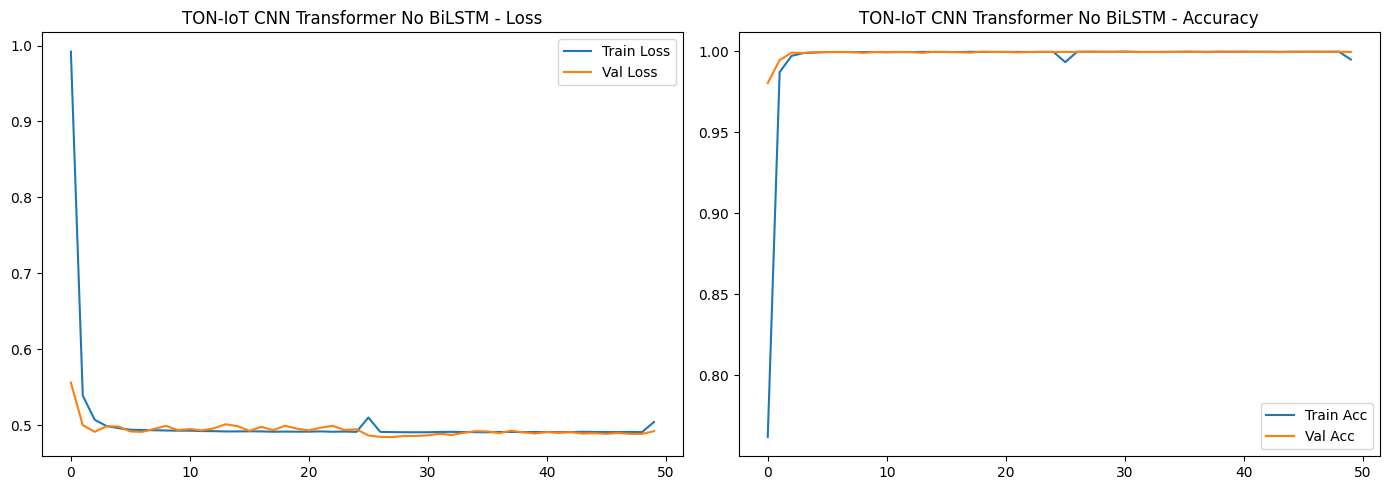

In [12]:
print("Training CNN+Transformer (No BiLSTM)...")
history_nb = train_model(model_no_bilstm, train_loader, val_loader,
                          CONFIG['epochs'], save_path='toniot_no_bilstm_best.pth')
plot_history(history_nb, "TON-IoT CNN Transformer No BiLSTM")

In [13]:
print("Fitting MinMax Gate for CNN+Transformer (No BiLSTM)...")
train_feats_nb, train_labels_nb = get_prob_features(model_no_bilstm, train_loader, device)
gate_nb = MinMaxThreeWayGate(q=9).fit(train_feats_nb, train_labels_nb)
print(f"Gate fitted | feats shape: {train_feats_nb.shape}")

Fitting MinMax Gate for CNN+Transformer (No BiLSTM)...
Gate fitted | feats shape: (133000, 8)



  EVALUATION: TON-IoT CNN + Transformer (No BiLSTM)

  Total test samples  : 48500
  Predicted Emerging  : 20359 (excluded)
  Evaluated samples   : 28141

  Accuracy : 1.0000
  Precision: 1.0000
  Recall   : 1.0000
  F1-Score : 1.0000

  Classification Report (Emerging excluded):
              precision    recall  f1-score   support

    Backdoor       1.00      1.00      1.00      2992
        DDos       1.00      1.00      1.00      2965
         Dos       1.00      1.00      1.00      2941
   Injection       1.00      1.00      1.00      2982
      Normal       1.00      1.00      1.00      7293
    Password       1.00      1.00      1.00      2982
  Ransomware       1.00      1.00      1.00      2994
         XSS       1.00      1.00      1.00      2992

    accuracy                           1.00     28141
   macro avg       1.00      1.00      1.00     28141
weighted avg       1.00      1.00      1.00     28141



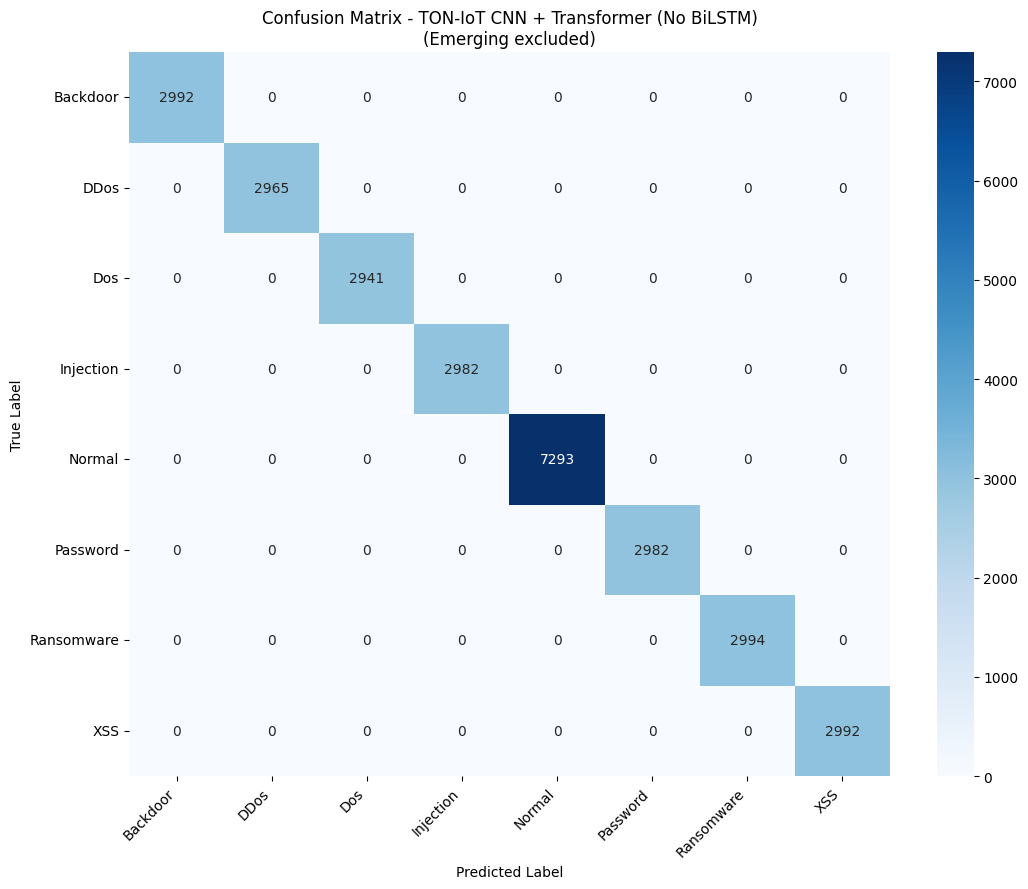

In [14]:
results_nb = evaluate_model(model_no_bilstm, test_loader, gate_nb, le,
                             y_test_final_str, "TON-IoT CNN + Transformer (No BiLSTM)")